In [ ]:
import numpy as np
import heapq
import matplotlib.pyplot as plt

In [26]:
# --- Step 1: Create Occupancy Grid ---
size = 20
garden = np.zeros((size+5, size))  # 0 = free, 1 = obstacle

# Add some obstacles
obstacles = [(5, y) for y in range(5, 15)] + [(12, y) for y in range(0, 10)]
for (x, y) in obstacles:
    garden[y, x] = 1

In [27]:
def astar(grid, start, goal):
    """A* pathfinding from start to goal on a grid."""
    rows, cols = grid.shape
    open_set = []
    heapq.heappush(open_set, (0, start))
    came_from = {}
    g_score = {start: 0}
    directions = [(-1,0),(1,0),(0,-1),(0,1)]  # 4-connectivity

    while open_set:
        _, current = heapq.heappop(open_set)
        if current == goal:
            # reconstruct path
            path = []
            while current in came_from:
                path.append(current)
                current = came_from[current]
            path.append(start)
            return path[::-1]
        for dx, dy in directions:
            neighbor = (current[0]+dx, current[1]+dy)
            if 0 <= neighbor[0] < cols and 0 <= neighbor[1] < rows:
                if grid[neighbor[1], neighbor[0]] == 1:
                    continue  # obstacle
                tentative_g = g_score[current] + 1
                if neighbor not in g_score or tentative_g < g_score[neighbor]:
                    g_score[neighbor] = tentative_g
                    f_score = tentative_g + abs(goal[0]-neighbor[0]) + abs(goal[1]-neighbor[1])
                    heapq.heappush(open_set, (f_score, neighbor))
                    came_from[neighbor] = current
    return []  # no path found

def coverage_path_with_astar(grid, stroke_diameter, overlap_percent):
    rows, cols = grid.shape
    path = []
    step = stroke_diameter * (1 - overlap_percent / 100)
    step = max(1, int(round(step)))
    start_y = step // 2

    direction = 1
    prev_end = None
    for y in range(start_y, rows, step):
        if direction == 1:
            x_range = range(cols)
        else:
            x_range = range(cols - 1, -1, -1)
        row_points = [(x, y) for x in x_range if grid[y, x] == 0]
        if not row_points:
            continue
        if prev_end:
            # Connect previous row end to current row start using A*
            astar_path = astar(grid, prev_end, row_points[0])
            if astar_path:
                path.extend(astar_path[1:])  # skip duplicate point
        path.extend(row_points)
        prev_end = row_points[-1]
        direction *= -1
    return path

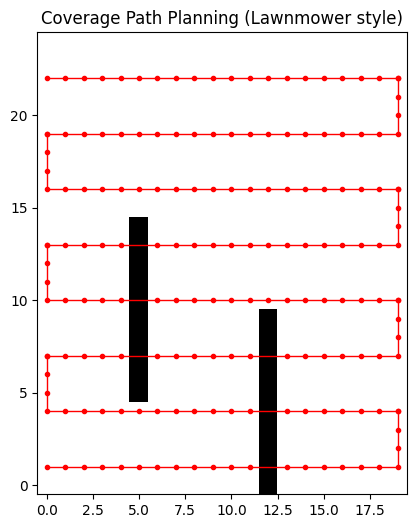

In [29]:
#path = coverage_path(garden)
#path = coverage_path_efficient(garden, stroke_diameter=4, overlap_percent=20)
path = coverage_path_with_astar(garden, stroke_diameter=4, overlap_percent=20)

# --- Step 3: Visualization ---
fig, ax = plt.subplots(figsize=(6, 6))
#ax.imshow(garden, cmap="gray_r")  # white=free, black=obstacle
# transpose for proper orientation
ax.imshow(garden, cmap="Greys", origin="lower")

# Show path
px, py = zip(*path)
ax.plot(px, py, "r.-", linewidth=1)
ax.set_title("Coverage Path Planning (Lawnmower style)")
plt.show()